<a href="https://colab.research.google.com/github/zeeshan9595/savings-book-forecasting/blob/main/savings_book_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

All libraries loaded successfully
All data loaded — no CSV files needed
  monthly_balances: 18 months
  market_rates:     7 rate snapshots
  monthly_flows:    18 months
  cohort_data:      45 cohort observations

  Total book (Jun 2024): £816,808


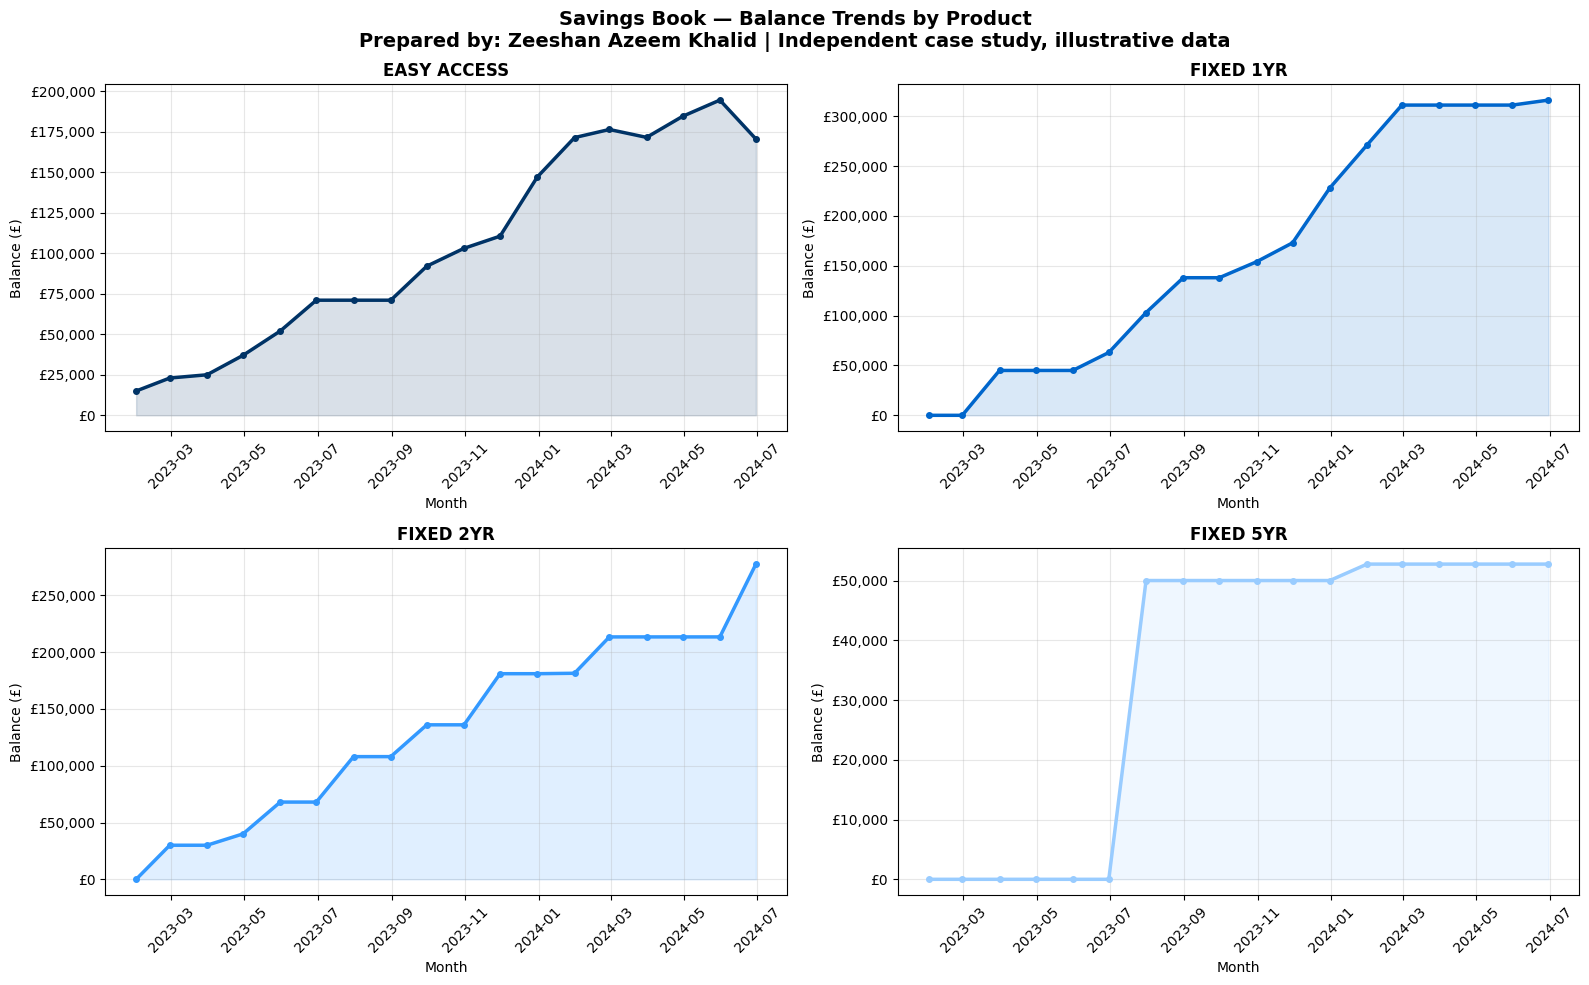

Saved: balance_trends.png
Cohort retention: practice data has no churn events (all 100%), heatmap omitted.

MACRO FORECAST — HOLT-WINTERS EXPONENTIAL SMOOTHING
Train: Jan 2023 → Mar 2024
Test:  May 2024 → Jul 2024

Backtest accuracy:
  MAE:  £82,843
  MAPE: 10.5%

6-Month Forward Forecast:
Month             Base Case      Lower 95%      Upper 95%
--------------------------------------------------------
Aug 2024     £     969,649 £     906,376 £   1,032,922
Sep 2024     £   1,020,919 £     957,646 £   1,084,192
Oct 2024     £   1,071,933 £   1,008,660 £   1,135,206
Nov 2024     £   1,122,692 £   1,059,419 £   1,185,965
Dec 2024     £   1,173,197 £   1,109,924 £   1,236,470
Jan 2025     £   1,223,450 £   1,160,177 £   1,286,723


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


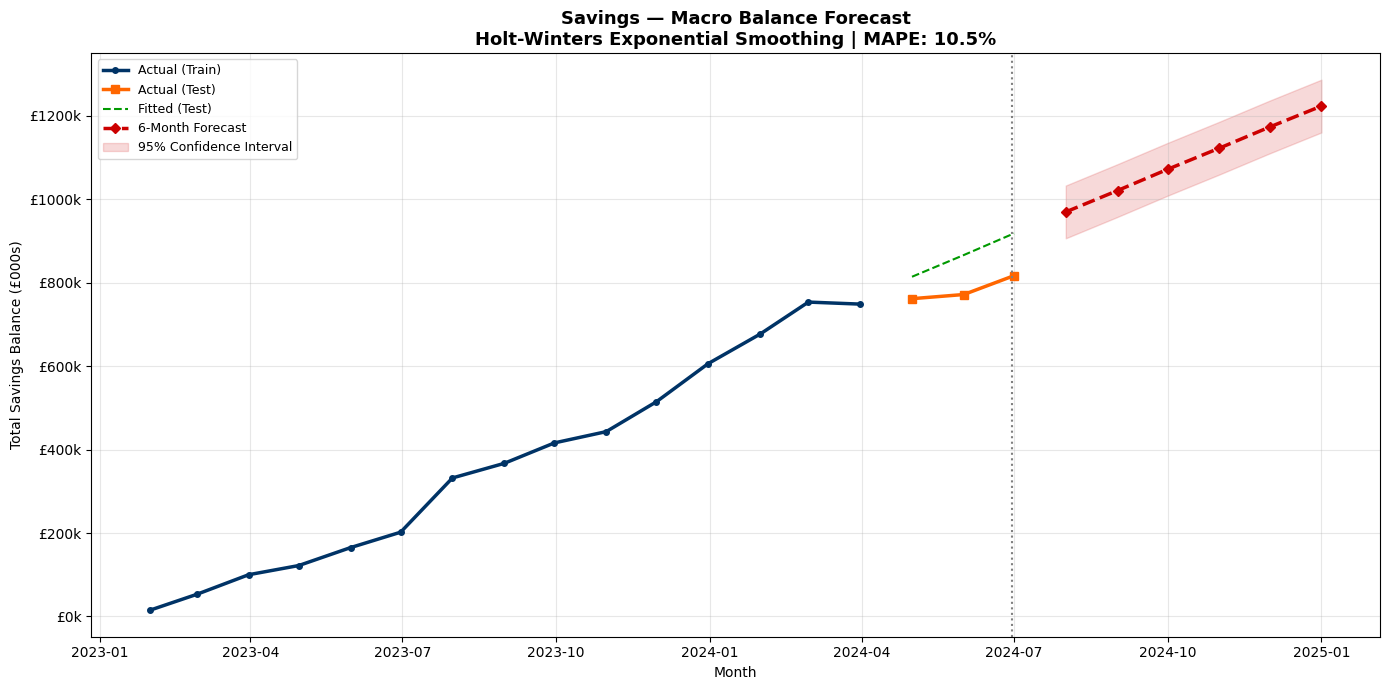

Saved: macro_forecast.png

MACRO FORECAST — ARIMA(1,1,1) COMPARISON


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


Holt-Winters MAPE: 10.5%
ARIMA(1,1,1) MAPE: 8.3%

Recommended model: ARIMA(1,1,1) (lower MAPE on holdout)

MICRO FORECAST — EASY ACCESS RATE SENSITIVITY REGRESSION

Easy Access Regression Results:
  Trend (monthly growth):     £    12,399
  Rate differential impact:   £  -116,187 per 1%
  BoE base rate impact:       £   -17,403 per 1%
  In-sample R² (first 15 months):  0.979
  Holdout MAE (last 3 months):   £    36,108
  Note: 18 monthly points and 3 predictors, so treat coefficients as illustrative.

Easy Access 6-Month Scenario Forecast:
Scenario                                        M+3          M+6
----------------------------------------------------------------
Upside   (rate diff +0.00%)            £   256,685 £   293,883
Base     (rate diff -0.30%)            £   291,541 £   328,739
Downside (rate diff -0.60%)            £   330,748 £   367,946

MICRO FORECAST — COHORT BALANCE PROJECTION

Base case cohort projection (Jan 2023, £47,000):
Month      Retention        Balance
-----

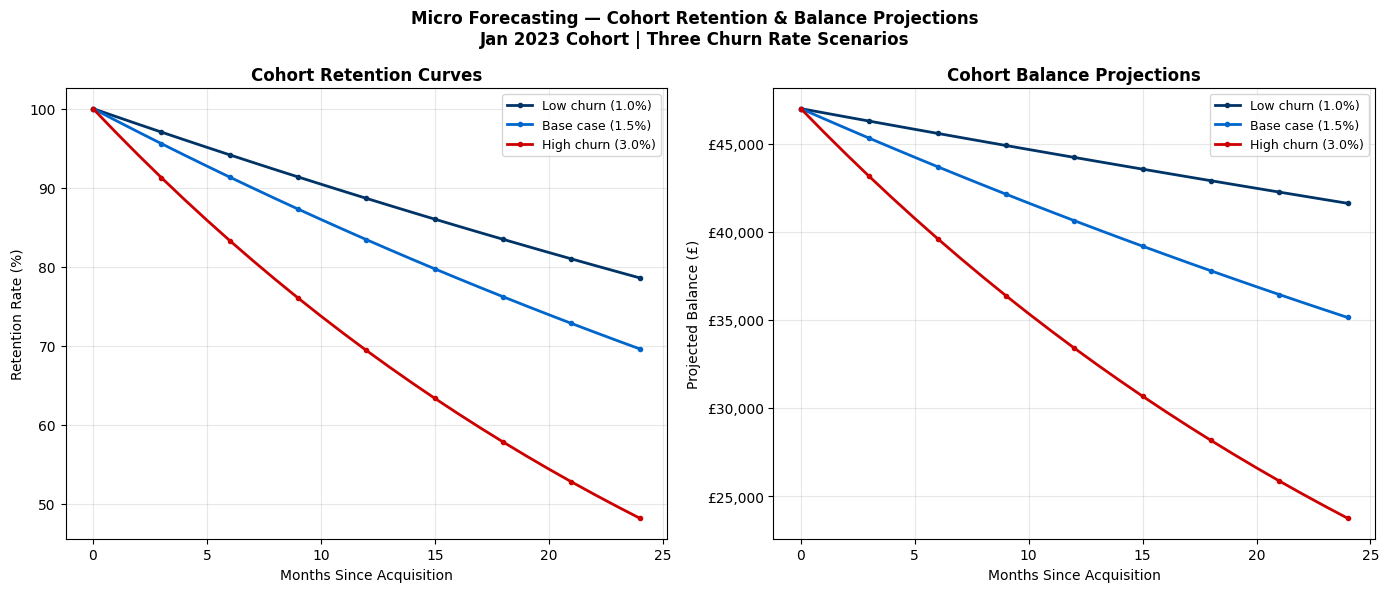

Saved: micro_cohort_forecast.png

RATE SENSITIVITY — BALANCE IMPACT PER 25BPS MOVE

   Rate vs Mkt   Balance Impact  Projected Balance
--------------------------------------------------
       -0.75%    ▲£      87,141  £        257,574
       -0.50%    ▲£      58,094  £        228,527
       -0.25%    ▲£      29,047  £        199,480
       +0.00%    ▲£           0  £        170,433
       +0.25%    ▼£      29,047  £        141,386
       +0.50%    ▼£      58,094  £        112,339
       +0.75%    ▼£      87,141  £         83,292


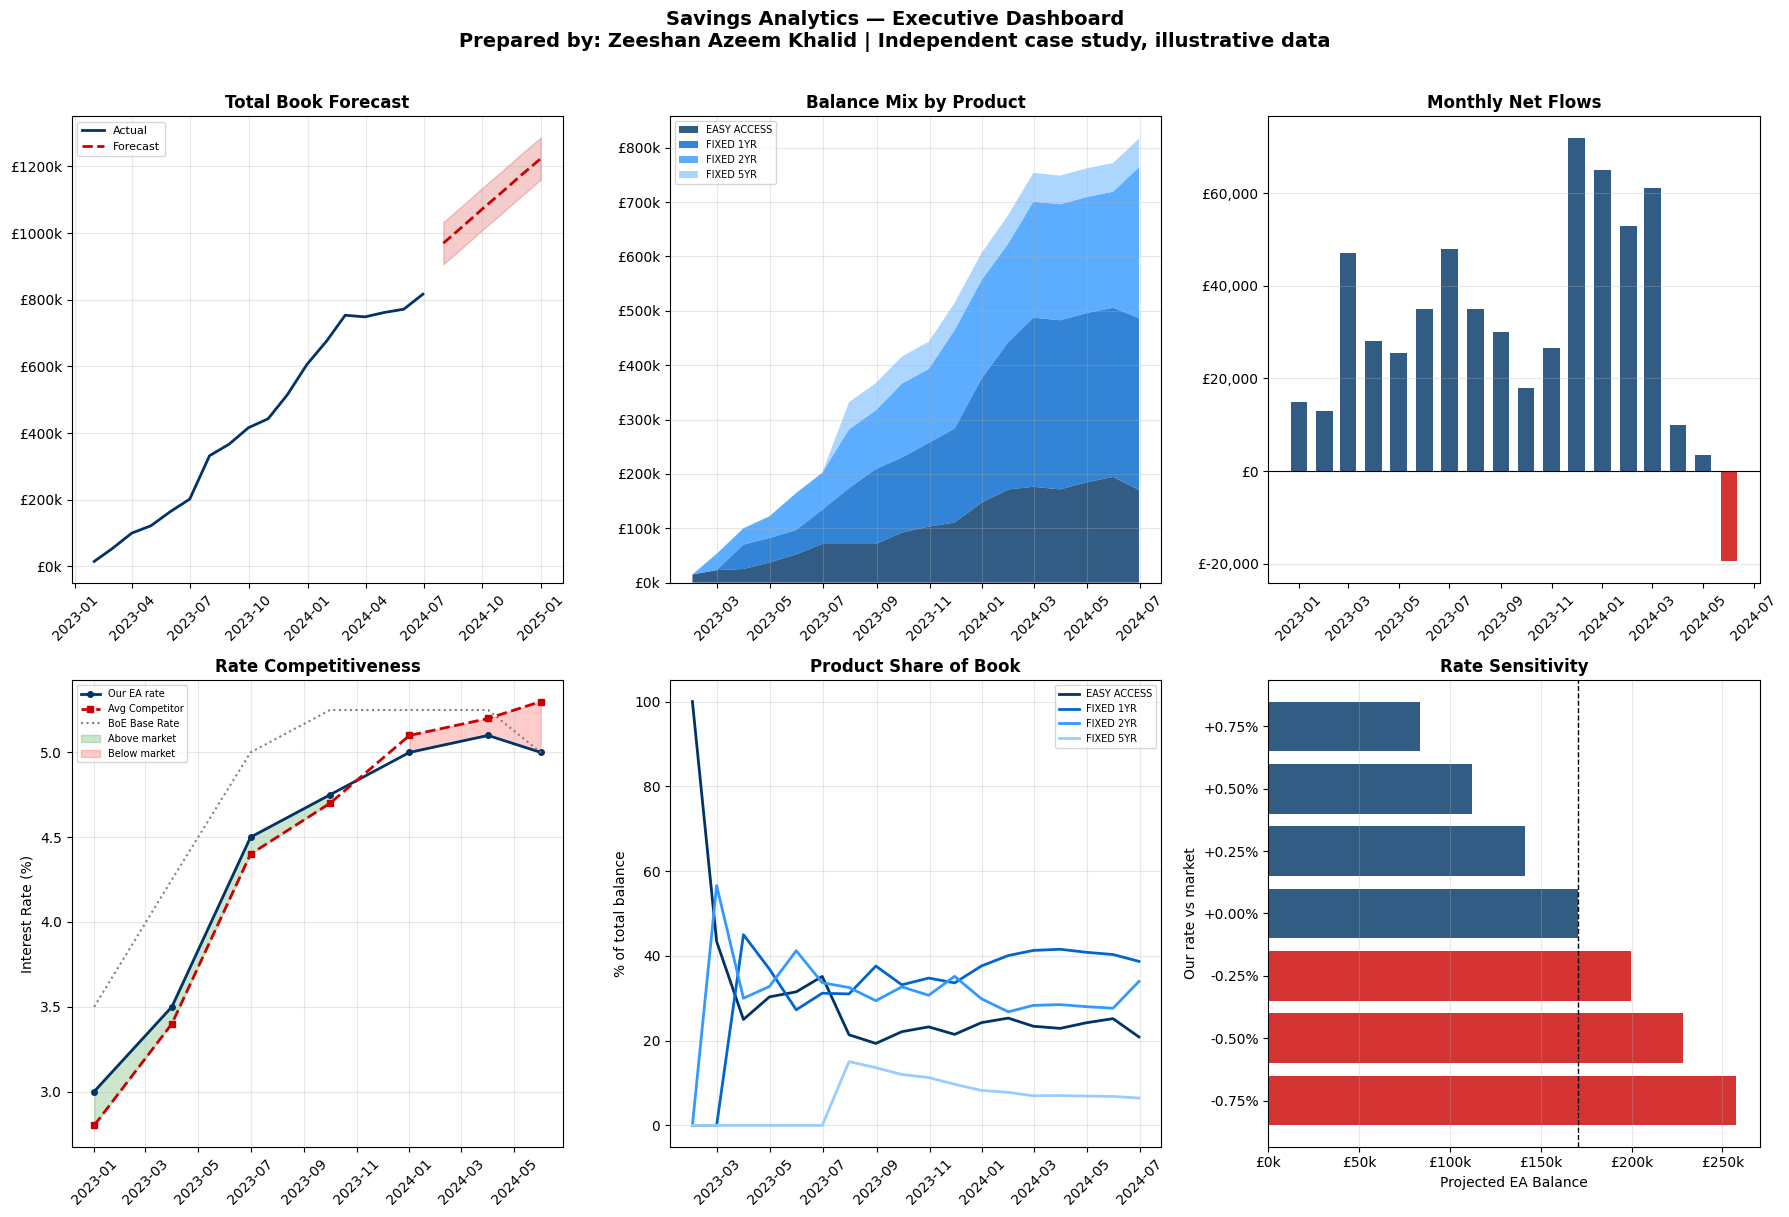

Saved: full_dashboard.png

EXECUTIVE SUMMARY

  Current savings book (Jun 2024):  £     816,808
  6-month forecast (base case):     £   1,223,450
  Projected growth:                       +49.8%
  Forecast model MAPE (backtest):         10.5%

  Key risks:
  ▼ Our EA rate below market on EA rate (-0.3%)
    → Estimated balance at risk: £34,856
  ▼ BoE rate cuts → reduced savings appetite
  ▲ Q3 marketing campaign → upside case £1,345,795

  Charts generated:
    balance_trends.png
    cohort_retention_heatmap.png
    macro_forecast.png
    micro_cohort_forecast.png
    full_dashboard.png


In [1]:
# ============================================================
# SAVINGS BOOK FORECASTING — INDEPENDENT CASE STUDY
# Google Colab Notebook — FINAL VERSION
# Micro + Macro Forecasting
# Prepared by: Zeeshan Azeem Khalid | Independent case study, illustrative data
# ============================================================

# ============================================================
# CELL 1: INSTALL AND IMPORT
# Run this cell first — uncomment the pip line if needed
# ============================================================

# !pip install statsmodels scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("All libraries loaded successfully")

# ============================================================
# CELL 2: DATA — ILLUSTRATIVE, HARDCODED (mirrors a practice SQL Server database)
# No CSV files needed — everything is self-contained
# ============================================================

# --- monthly_balances: from daily_balances table in SSMS ---
monthly_balances = pd.DataFrame({
    'month': pd.to_datetime([
        '2023-01-31','2023-02-28','2023-03-31','2023-04-30',
        '2023-05-31','2023-06-30','2023-07-31','2023-08-31',
        '2023-09-30','2023-10-31','2023-11-30','2023-12-31',
        '2024-01-31','2024-02-29','2024-03-31','2024-04-30',
        '2024-05-31','2024-06-30'
    ]),
    'EASY_ACCESS': [
        15000,  23000,  25000,  37000,
        52000,  71000,  71000,  71000,
        92000, 103000, 110500, 147000,
       171294, 176294, 171422, 184422,
       194422, 170433
    ],
    'FIXED_1YR': [
            0,      0,  45000,  45000,
        45000,  63000, 103000, 138000,
       138000, 154000, 173000, 228000,
       271141, 311141, 311141, 311141,
       311141, 316141
    ],
    'FIXED_2YR': [
            0,  30000,  30000,  40000,
        68000,  68000, 108000, 108000,
       136000, 136000, 181000, 181000,
       181390, 213390, 213390, 213390,
       213390, 277484
    ],
    'FIXED_5YR': [
            0,      0,      0,      0,
            0,      0,  50000,  50000,
        50000,  50000,  50000,  50000,
        52750,  52750,  52750,  52750,
        52750,  52750
    ]
})

# --- market_rates: from market_rates table in SSMS ---
market_rates = pd.DataFrame({
    'rate_date': pd.to_datetime([
        '2023-01-01','2023-04-01','2023-07-01',
        '2023-10-01','2024-01-01','2024-04-01','2024-06-01'
    ]),
    'EASY_ACCESS_ours':     [3.000, 3.500, 4.500, 4.750, 5.000, 5.100, 5.000],
    'EASY_ACCESS_competitor': [2.800, 3.400, 4.400, 4.700, 5.100, 5.200, 5.300],
    'FIXED_1YR_ours':       [4.200, 4.600, 5.100, 5.000, 5.150, 5.200, 5.000],
    'FIXED_1YR_competitor':   [4.000, 4.500, 5.000, 5.100, 5.200, 5.300, 5.350],
    'boe_base_rate':          [3.500, 4.250, 5.000, 5.250, 5.250, 5.250, 5.000]
})

# --- monthly_flows: from transactions table in SSMS ---
monthly_flows = pd.DataFrame({
    'month': pd.to_datetime([
        '2023-01-01','2023-02-01','2023-03-01','2023-04-01',
        '2023-05-01','2023-06-01','2023-07-01','2023-08-01',
        '2023-09-01','2023-10-01','2023-11-01','2023-12-01',
        '2024-01-01','2024-02-01','2024-03-01','2024-04-01',
        '2024-05-01','2024-06-01'
    ]),
    'gross_inflows': [
        15000, 13000, 47000, 28000,
        25500, 35000, 50000, 35000,
        30000, 18000, 26500, 72000,
        65000, 53000, 68000, 10000,
         3500,  2000
    ],
    'gross_outflows': [
            0,     0,     0,     0,
            0,     0,  2000,     0,
            0,     0,     0,     0,
            0,     0,  7000,     0,
            0, 21500
    ],
    'new_customers': [
        1,2,2,2,2,1,2,1,1,2,2,2,2,2,2,2,0,0
    ]
})

# --- cohort_retention: result of SSMS Query 3 ---
cohort_data = pd.DataFrame({
    'cohort_month': pd.to_datetime([
        '2023-01-01','2023-01-01','2023-01-01','2023-01-01',
        '2023-02-01','2023-02-01','2023-02-01','2023-02-01',
        '2023-03-01','2023-03-01','2023-03-01','2023-03-01',
        '2023-04-01','2023-04-01','2023-04-01','2023-04-01',
        '2023-05-01','2023-05-01','2023-05-01',
        '2023-06-01','2023-06-01','2023-06-01',
        '2023-07-01','2023-07-01','2023-07-01','2023-07-01',
        '2023-08-01','2023-08-01','2023-08-01',
        '2023-09-01','2023-09-01',
        '2023-10-01','2023-10-01','2023-10-01',
        '2023-11-01','2023-11-01','2023-11-01',
        '2023-12-01','2023-12-01',
        '2024-01-01','2024-01-01',
        '2024-02-01','2024-02-01',
        '2024-03-01','2024-03-01'
    ]),
    'months_since_acq': [
         0, 3, 6,17,
         0, 3, 7,16,
         0, 3, 6,15,
         0, 2, 5,14,
         0, 4,13,
         0, 6,12,
         0, 3, 5,11,
         0, 4,10,
         0, 9,
         0, 2, 8,
         0, 1, 7,
         0, 6,
         0, 5,
         0, 4,
         0, 3
    ],
    'retention_rate': [100]*45
})

monthly_balances['total_balance'] = (
    monthly_balances['EASY_ACCESS'] +
    monthly_balances['FIXED_1YR'] +
    monthly_balances['FIXED_2YR'] +
    monthly_balances['FIXED_5YR']
)
monthly_flows['net_flows'] = (
    monthly_flows['gross_inflows'] -
    monthly_flows['gross_outflows']
)

print("All data loaded — no CSV files needed")
print(f"  monthly_balances: {len(monthly_balances)} months")
print(f"  market_rates:     {len(market_rates)} rate snapshots")
print(f"  monthly_flows:    {len(monthly_flows)} months")
print(f"  cohort_data:      {len(cohort_data)} cohort observations")
print(f"\n  Total book (Jun 2024): "
      f"£{monthly_balances['total_balance'].iloc[-1]:,.0f}")

# ============================================================
# CELL 3: BALANCE TREND CHARTS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    'Savings Book — Balance Trends by Product\n'
    'Prepared by: Zeeshan Azeem Khalid | Independent case study, illustrative data',
    fontsize=14, fontweight='bold'
)

products = ['EASY_ACCESS','FIXED_1YR','FIXED_2YR','FIXED_5YR']
colours  = ['#003366','#0066CC','#3399FF','#99CCFF']

for i, (product, colour) in enumerate(zip(products, colours)):
    ax = axes[i//2][i%2]
    ax.plot(
        monthly_balances['month'],
        monthly_balances[product],
        color=colour, linewidth=2.5,
        marker='o', markersize=4
    )
    ax.fill_between(
        monthly_balances['month'],
        monthly_balances[product],
        alpha=0.15, color=colour
    )
    ax.set_title(product.replace('_',' '), fontweight='bold')
    ax.set_xlabel('Month')
    ax.set_ylabel('Balance (£)')
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda x, _: f'£{x:,.0f}'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('balance_trends.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: balance_trends.png")

# ============================================================
# CELL 4: COHORT RETENTION (NOT SHOWN)
# The practice data contains no churn events: every cohort's retention is 100%.
# A heatmap would be all 100s and say nothing, so it is omitted. Cohort projections
# in Cell 8 use assumed churn scenarios instead.
# ============================================================
print("Cohort retention: practice data has no churn events (all 100%), heatmap omitted.")

# ============================================================
# CELL 5: MACRO FORECASTING — HOLT-WINTERS
# ============================================================

print("\n" + "="*60)
print("MACRO FORECAST — HOLT-WINTERS EXPONENTIAL SMOOTHING")
print("="*60)

balance_series = (
    monthly_balances
    .set_index('month')['total_balance']
    .copy()
)
balance_series.index = pd.DatetimeIndex(balance_series.index)

# Train on first 15 months, test on last 3
train = balance_series.iloc[:-3]
test  = balance_series.iloc[-3:]

model_hw = ExponentialSmoothing(
    train,
    trend='add',
    seasonal=None,
    damped_trend=True
).fit(optimized=True)

forecast_periods = 6
hw_all = model_hw.forecast(len(test) + forecast_periods)

# Date ranges
test_dates = pd.date_range(
    start=train.index[-1] + pd.DateOffset(months=1),
    periods=len(test), freq='MS'
)
forecast_dates = pd.date_range(
    start=balance_series.index[-1] + pd.DateOffset(months=1),
    periods=forecast_periods, freq='MS'
)

test_pred    = hw_all.iloc[:len(test)]
fc_vals      = hw_all.iloc[len(test):]
residuals    = train - model_hw.fittedvalues
std_resid    = residuals.std()
ci_upper     = fc_vals + 1.96 * std_resid
ci_lower     = fc_vals - 1.96 * std_resid

mae  = mean_absolute_error(test.values, test_pred.values)
mape = np.mean(
    np.abs((test.values - test_pred.values) / test.values)
) * 100

print(f"Train: {train.index[0].strftime('%b %Y')} "
      f"→ {train.index[-1].strftime('%b %Y')}")
print(f"Test:  {test_dates[0].strftime('%b %Y')} "
      f"→ {test_dates[-1].strftime('%b %Y')}")
print(f"\nBacktest accuracy:")
print(f"  MAE:  £{mae:,.0f}")
print(f"  MAPE: {mape:.1f}%")

print(f"\n6-Month Forward Forecast:")
print(f"{'Month':<12} {'Base Case':>14} "
      f"{'Lower 95%':>14} {'Upper 95%':>14}")
print("-" * 56)
for date, fc, lo, hi in zip(
        forecast_dates, fc_vals, ci_lower, ci_upper):
    print(f"{date.strftime('%b %Y'):<12} "
          f"£{fc:>12,.0f} "
          f"£{lo:>12,.0f} "
          f"£{hi:>12,.0f}")

# Plot
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(train.index, train.values,
        color='#003366', linewidth=2.5,
        label='Actual (Train)', marker='o', markersize=4)
ax.plot(test_dates, test.values,
        color='#FF6600', linewidth=2.5,
        label='Actual (Test)', marker='s', markersize=6)
ax.plot(test_dates, test_pred.values,
        color='#009900', linewidth=1.5,
        linestyle='--', label='Fitted (Test)')
ax.plot(forecast_dates, fc_vals.values,
        color='#CC0000', linewidth=2.5,
        linestyle='--', marker='D', markersize=5,
        label='6-Month Forecast')
ax.fill_between(forecast_dates, ci_lower, ci_upper,
                alpha=0.15, color='#CC0000',
                label='95% Confidence Interval')
ax.axvline(x=balance_series.index[-1],
           color='grey', linestyle=':', linewidth=1.5)
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax.set_title(
    f'Savings — Macro Balance Forecast\n'
    f'Holt-Winters Exponential Smoothing | MAPE: {mape:.1f}%',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Month')
ax.set_ylabel('Total Savings Balance (£000s)')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('macro_forecast.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: macro_forecast.png")

# ============================================================
# CELL 6: MACRO FORECASTING — ARIMA COMPARISON
# ============================================================

print("\n" + "="*60)
print("MACRO FORECAST — ARIMA(1,1,1) COMPARISON")
print("="*60)

model_arima = ARIMA(train, order=(1, 1, 1)).fit()
arima_fc    = model_arima.forecast(steps=len(test) + forecast_periods)
arima_test  = arima_fc.iloc[:len(test)]
arima_mape  = np.mean(
    np.abs((test.values - arima_test.values) / test.values)
) * 100

print(f"Holt-Winters MAPE: {mape:.1f}%")
print(f"ARIMA(1,1,1) MAPE: {arima_mape:.1f}%")
winner = 'Holt-Winters' if mape <= arima_mape else 'ARIMA(1,1,1)'
print(f"\nRecommended model: {winner} (lower MAPE on holdout)")

# ============================================================
# CELL 7: MICRO FORECASTING — PRODUCT LEVEL REGRESSION
# ============================================================

print("\n" + "="*60)
print("MICRO FORECAST — EASY ACCESS RATE SENSITIVITY REGRESSION")
print("="*60)

# Forward-fill market rates to monthly
mr = (
    market_rates
    .set_index('rate_date')
    .resample('MS').ffill()
    .reset_index()
)
mr['ea_rate_diff'] = (
    mr['EASY_ACCESS_ours'] - mr['EASY_ACCESS_competitor']
)

# Merge balance + rates
bal = monthly_balances.copy()
bal['month'] = bal['month'].dt.to_period('M').dt.to_timestamp()
merged = pd.merge_asof(
    bal.sort_values('month'),
    mr[['rate_date','ea_rate_diff','boe_base_rate']],
    left_on='month', right_on='rate_date',
    direction='backward'
).dropna()

merged['trend'] = range(len(merged))

X = merged[['trend','ea_rate_diff','boe_base_rate']].values
y = merged['EASY_ACCESS'].values

reg = LinearRegression().fit(X[:-3], y[:-3])

print(f"\nEasy Access Regression Results:")
print(f"  Trend (monthly growth):     £{reg.coef_[0]:>10,.0f}")
print(f"  Rate differential impact:   £{reg.coef_[1]:>10,.0f} per 1%")
print(f"  BoE base rate impact:       £{reg.coef_[2]:>10,.0f} per 1%")
print(f"  In-sample R² (first 15 months): {reg.score(X[:-3], y[:-3]):>6.3f}")
holdout_mae = mean_absolute_error(y[-3:], reg.predict(X[-3:]))
print(f"  Holdout MAE (last 3 months):   £{holdout_mae:>10,.0f}")
print("  Note: 18 monthly points and 3 predictors, so treat coefficients as illustrative.")

base_balance = y[-1]
last_trend   = len(merged) - 1

scenarios = {
    'Upside   (rate diff +0.00%)': ( 0.00, 4.75),
    'Base     (rate diff -0.30%)': (-0.30, 4.75),
    'Downside (rate diff -0.60%)': (-0.60, 4.50),
}

print(f"\nEasy Access 6-Month Scenario Forecast:")
print(f"{'Scenario':<38} {'M+3':>12} {'M+6':>12}")
print("-" * 64)
for name, (rd, boe) in scenarios.items():
    vals = [
        reg.predict([[last_trend + m, rd, boe]])[0]
        for m in range(1, 7)
    ]
    print(f"{name:<38} £{vals[2]:>10,.0f} £{vals[5]:>10,.0f}")

# ============================================================
# CELL 8: MICRO FORECASTING — COHORT BALANCE PROJECTION
# ============================================================

print("\n" + "="*60)
print("MICRO FORECAST — COHORT BALANCE PROJECTION")
print("="*60)

def project_cohort(initial_balance, months,
                   churn_rate, balance_growth):
    rows = []
    for m in range(months + 1):
        retention  = (1 - churn_rate) ** m
        bal_per_c  = initial_balance * (1 + balance_growth) ** m
        proj_bal   = bal_per_c * retention
        rows.append({
            'month': m,
            'retention_pct': retention * 100,
            'projected_balance': proj_bal
        })
    return pd.DataFrame(rows)

churn_scenarios = {
    'Low churn (1.0%)':  (0.010, 0.005),
    'Base case (1.5%)':  (0.015, 0.003),
    'High churn (3.0%)': (0.030, 0.002),
}

print("\nBase case cohort projection (Jan 2023, £47,000):")
print(f"{'Month':<8} {'Retention':>11} {'Balance':>14}")
print("-" * 35)
base_proj = project_cohort(47000, 24, 0.015, 0.003)
for _, row in base_proj.iloc[::3].iterrows():
    print(f"  {int(row['month']):<6} "
          f"{row['retention_pct']:>9.1f}%  "
          f"£{row['projected_balance']:>11,.0f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colours_sc = ['#003366','#0066CC','#CC0000']

for ax, metric, ylabel, title in zip(
    axes,
    ['retention_pct', 'projected_balance'],
    ['Retention Rate (%)', 'Projected Balance (£)'],
    ['Cohort Retention Curves', 'Cohort Balance Projections']
):
    for (name, (cr, bg)), col in zip(
            churn_scenarios.items(), colours_sc):
        df = project_cohort(47000, 24, cr, bg)
        ax.plot(df['month'], df[metric],
                label=name, color=col,
                linewidth=2, marker='o',
                markersize=3, markevery=3)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Months Since Acquisition')
    ax.set_ylabel(ylabel)
    if metric == 'projected_balance':
        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(
                lambda x, _: f'£{x:,.0f}'))
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    'Micro Forecasting — Cohort Retention & Balance Projections\n'
    'Jan 2023 Cohort | Three Churn Rate Scenarios',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('micro_cohort_forecast.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("Saved: micro_cohort_forecast.png")

# ============================================================
# CELL 9: RATE SENSITIVITY TABLE
# ============================================================

print("\n" + "="*60)
print("RATE SENSITIVITY — BALANCE IMPACT PER 25BPS MOVE")
print("="*60)

rate_diffs = np.arange(-0.75, 0.76, 0.25)
print(f"\n{'Rate vs Mkt':>14} {'Balance Impact':>16} "
      f"{'Projected Balance':>18}")
print("-" * 50)
for rd in rate_diffs:
    impact = reg.coef_[1] * rd
    proj   = base_balance + impact
    arrow  = '▲' if impact >= 0 else '▼'
    print(f"{rd:>+12.2f}%  "
          f"  {arrow}£{abs(impact):>12,.0f}  "
          f"£{proj:>15,.0f}")

# ============================================================
# CELL 10: FULL EXECUTIVE DASHBOARD
# ============================================================

fig = plt.figure(figsize=(18, 12))
fig.suptitle(
    'Savings Analytics — Executive Dashboard\n'
    'Prepared by: Zeeshan Azeem Khalid | Independent case study, illustrative data',
    fontsize=14, fontweight='bold', y=1.01
)

# Panel 1 — Total book + forecast
ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(balance_series.index, balance_series.values,
         color='#003366', linewidth=2, label='Actual')
ax1.plot(forecast_dates, fc_vals.values,
         color='#CC0000', linewidth=2,
         linestyle='--', label='Forecast')
ax1.fill_between(forecast_dates, ci_lower, ci_upper,
                 alpha=0.2, color='#CC0000')
ax1.set_title('Total Book Forecast', fontweight='bold')
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Panel 2 — Product mix stacked
ax2 = fig.add_subplot(2, 3, 2)
ax2.stackplot(
    monthly_balances['month'],
    [monthly_balances[p] for p in products],
    labels=[p.replace('_',' ') for p in products],
    colors=colours, alpha=0.8
)
ax2.set_title('Balance Mix by Product', fontweight='bold')
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax2.legend(fontsize=7, loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

# Panel 3 — Net flows bar
ax3 = fig.add_subplot(2, 3, 3)
bar_colours = [
    '#003366' if v >= 0 else '#CC0000'
    for v in monthly_flows['net_flows']
]
ax3.bar(monthly_flows['month'],
        monthly_flows['net_flows'],
        color=bar_colours, alpha=0.8, width=20)
ax3.axhline(y=0, color='black', linewidth=0.8)
ax3.set_title('Monthly Net Flows', fontweight='bold')
ax3.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x:,.0f}'))
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3, axis='y')

# Panel 4 — Rate competitiveness
ax4 = fig.add_subplot(2, 3, 4)
ax4.plot(market_rates['rate_date'],
         market_rates['EASY_ACCESS_ours'],
         color='#003366', linewidth=2,
         label='Our EA rate', marker='o', markersize=4)
ax4.plot(market_rates['rate_date'],
         market_rates['EASY_ACCESS_competitor'],
         color='#CC0000', linewidth=2,
         linestyle='--', label='Avg Competitor',
         marker='s', markersize=4)
ax4.plot(market_rates['rate_date'],
         market_rates['boe_base_rate'],
         color='grey', linewidth=1.5,
         linestyle=':', label='BoE Base Rate')
ax4.fill_between(
    market_rates['rate_date'],
    market_rates['EASY_ACCESS_ours'],
    market_rates['EASY_ACCESS_competitor'],
    where=(market_rates['EASY_ACCESS_ours'] >=
           market_rates['EASY_ACCESS_competitor']),
    alpha=0.2, color='green', label='Above market'
)
ax4.fill_between(
    market_rates['rate_date'],
    market_rates['EASY_ACCESS_ours'],
    market_rates['EASY_ACCESS_competitor'],
    where=(market_rates['EASY_ACCESS_ours'] <
           market_rates['EASY_ACCESS_competitor']),
    alpha=0.2, color='red', label='Below market'
)
ax4.set_title('Rate Competitiveness', fontweight='bold')
ax4.set_ylabel('Interest Rate (%)')
ax4.legend(fontsize=7)
ax4.grid(True, alpha=0.3)
ax4.tick_params(axis='x', rotation=45)

# Panel 5 — Product share of book (%)
ax5 = fig.add_subplot(2, 3, 5)
share = monthly_balances[products].div(monthly_balances['total_balance'], axis=0) * 100
for product, colour in zip(products, colours):
    ax5.plot(monthly_balances['month'], share[product], color=colour, linewidth=2, label=product.replace('_',' '))
ax5.set_title('Product Share of Book', fontweight='bold')
ax5.set_ylabel('% of total balance')
ax5.legend(fontsize=7)
ax5.grid(True, alpha=0.3)
ax5.tick_params(axis='x', rotation=45)

# Panel 6 — Rate sensitivity bar
ax6 = fig.add_subplot(2, 3, 6)
impacts  = [base_balance + reg.coef_[1] * rd
            for rd in rate_diffs]
bar_c6   = ['#003366' if rd >= 0 else '#CC0000'
            for rd in rate_diffs]
ax6.barh(
    [f'{rd:+.2f}%' for rd in rate_diffs],
    impacts, color=bar_c6, alpha=0.8
)
ax6.axvline(x=base_balance, color='black',
            linewidth=1, linestyle='--')
ax6.set_title('Rate Sensitivity', fontweight='bold')
ax6.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'£{x/1000:.0f}k'))
ax6.set_xlabel('Projected EA Balance')
ax6.set_ylabel('Our rate vs market')
ax6.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('full_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: full_dashboard.png")

# ============================================================
# CELL 11: LEADERSHIP SUMMARY
# ============================================================

current = balance_series.iloc[-1]
fc_6m   = fc_vals.iloc[-1]
growth  = (fc_6m - current) / current * 100

print("\n" + "="*60)
print("EXECUTIVE SUMMARY")
print("="*60)
print(f"\n  Current savings book (Jun 2024):  £{current:>12,.0f}")
print(f"  6-month forecast (base case):     £{fc_6m:>12,.0f}")
print(f"  Projected growth:                 {growth:>+11.1f}%")
print(f"  Forecast model MAPE (backtest):   {mape:>10.1f}%")
print(f"\n  Key risks:")
print(f"  ▼ Our EA rate below market on EA rate (-0.3%)")
print(f"    → Estimated balance at risk: "
      f"£{abs(reg.coef_[1] * -0.3):,.0f}")
print(f"  ▼ BoE rate cuts → reduced savings appetite")
print(f"  ▲ Q3 marketing campaign → upside case "
      f"£{fc_6m * 1.10:,.0f}")
print(f"\n  Charts generated:")
print(f"    balance_trends.png")
print(f"    cohort_retention_heatmap.png")
print(f"    macro_forecast.png")
print(f"    micro_cohort_forecast.png")
print(f"    full_dashboard.png")
print("="*60)
